**Lab 3** for the course of *Selected Topics in Music and Acoustic Engineering* :

***Machine Learning for Audio and Acoustic Engineering***
---

* Student 1: Jorge Cuartero Galindo
* Student 2: Giuliano Di Lorenzo

# **Before you start**

*   Go to "*File*" --> "*Save a copy in Drive*"
*   Open that copy (might open automatically)
*   Then continue below

# **Lab 3: Neural Networks**

In this lab we will start to work with deep learning models. We will begin by looking at simple examples with synthetically generated data. Then, you will move to a more challenging and realistic problem.


### **Exercise 1**: Approximating Synthetic Data

Execute the following lines for create a synthetically generated dataset:

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import librosa
import sklearn
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
plt.style.use("seaborn-v0_8")

In [ ]:
def gen_data(size, a, b):
  x = np.random.rand(size,1)-0.5
  y = a*x + b
  y = y*(x>0)
  y = y + 0.2*(np.random.randn(*x.shape))
  return x, y

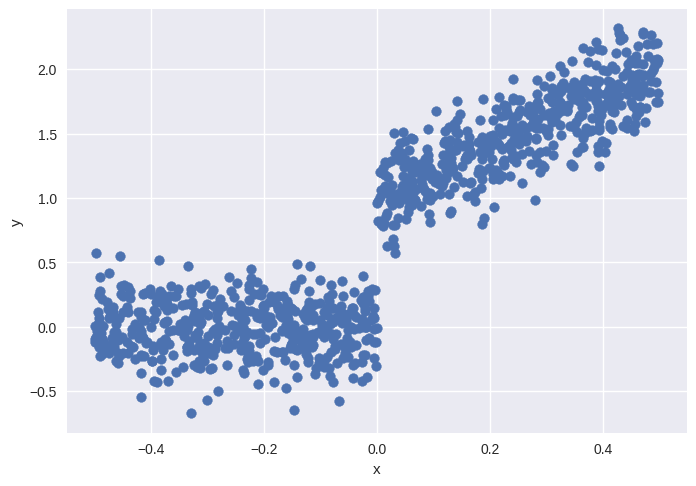

In [ ]:
# Create data and plot
Xdata, Ydata = gen_data(1000, 2, 1)
plt.scatter(Xdata,Ydata);
plt.xlabel('x');
plt.ylabel('y');

Describe the function underlying the model used to generate the data. Complete the symbols "?"

\begin{equation}
    y(x)=\begin{cases}
        2 \cdot x + 1 + 0.2 \cdot \mathcal{N}(0, 1) & x >0 \\
        0.2 \cdot \mathcal{N}(0, 1), & x<0
    \end{cases}, \quad \text{where } x \in \mathcal{U}(0, 1) - 0.5
\end{equation}


### **Exercise 2**: Create a MLP neural network model using Keras

Create the following fully-connected feedforward network using Keras' sequential model. Use:

| Layer | Type  | Units | Activation | Description                                                  |
|-------|-------|-------|------------|--------------------------------------------------------------|
| 1     | Dense | 5     | ReLU       | First hidden layer with 5 neurons, applies non-linearity     |
| 2     | Dense | 5     | ReLU       | Second hidden layer, also with 5 neurons                     |
| 3     | Dense | 1     | Linear     | Output layer, returns a single continuous value (regression) |

Show the model's summary.

![](https://drive.google.com/uc?export=view&id=1UJwycQXQG8kkF0N8CmDW-ED-hY-Uck5o)



In [8]:
import keras
from keras import layers
from keras import ops

model = keras.Sequential([
        layers.Dense(5, activation="relu", input_shape=(1,), name="layer1"),
        layers.Dense(5, activation="relu", name="layer2"),
        layers.Dense(1, activation="linear", name="layer3"),
])

/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


How many parameters has the model?  (Hint: use the function model.summary())

In [ ]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ layer1 (Dense)                  │ (None, 5)              │            10 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer2 (Dense)                  │ (None, 5)              │            30 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer3 (Dense)                  │ (None, 1)              │             6 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 46 (184.00 B)

 Trainable params: 46 (184.00 B)

 Non-trainable params: 0 (0.00 B)

### Observation

The number of parameters is $10+30+6 = 46$.

Layer 1 has $5$ weights and $5$ biases.
Layer 2 has $5 \times 5$ weights and $5$ biases.
Layer 3 has $5$ weights and $1$ bias.

Compile the model and train it on Xdata using MSE as the loss function and SGD optimizer with learning rate 0.01. Train the model until reaching 300 epochs.

In [ ]:
model.compile(
    optimizer=keras.optimizers.SGD(learning_rate=0.01),
    loss='mse',
    metrics=['mse']
)

history = model.fit(Xdata, Ydata, epochs=300);

Epoch 1/300
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.9844 - mse: 0.9844
Epoch 2/300
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.3925 - mse: 0.3925
Epoch 3/300
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.2797 - mse: 0.2797
Epoch 4/300
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.2148 - mse: 0.2148
Epoch 5/300
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.1616 - mse: 0.1616
Epoch 6/300
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.1211 - mse: 0.1211
Epoch 7/300
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.1077 - mse: 0.1077
Epoch 8/300
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0931 - mse: 0.0931
Epoch 9/300
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0851 - mse: 0.0851
Epoch 10/300
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0832 - mse: 0.0832
Epoch 11/300
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0750 - mse: 0.0750
Epoch 12/300
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0801 - mse: 0.0801
Epoch 13/300
32/32 ━━━━━━━━━━━━━━━━━━

Plot the training history of the network, showing the evolution of the training loss.

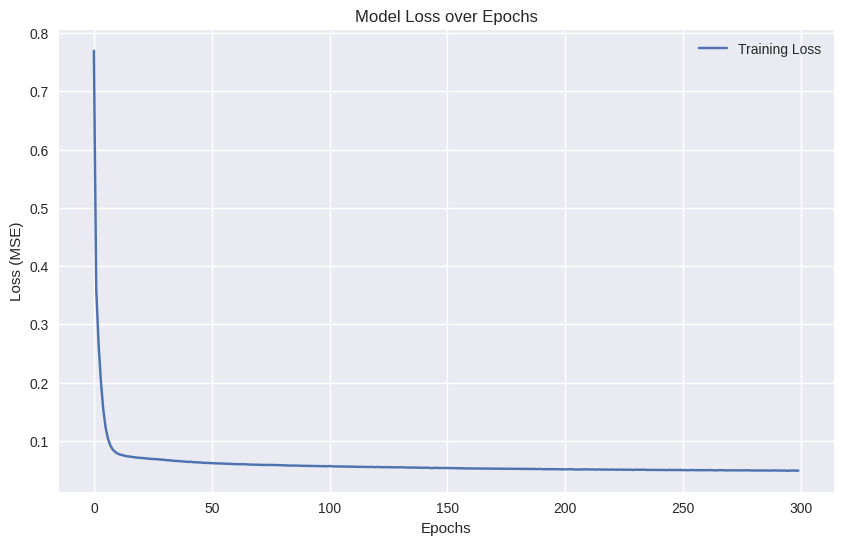

In [ ]:
plt.figure(figsize=(10, 6))
plt.plot(history.history['loss'], label='Training Loss')
if 'val_loss' in history.history:
    plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss over Epochs')
plt.xlabel('Epochs')
plt.ylabel('Loss (MSE)')
plt.legend()
plt.grid(True)
plt.show()

Which is the minimum loss achieved by the model? At which epoch achieved that loss value?

In [ ]:
min_loss = np.min(history.history['loss'])
min_loss_index = np.where(history.history['loss'] == min_loss)

print('Minimum Loss on the Training Set: ', min_loss , ' obtained at epoch: ' , ''.join(map(str, min_loss_index[0]+1))) #Index goes from 0 but epochs start at 1

Minimum Loss on the Training Set:  0.04876426234841347  obtained at epoch:  295


Plot the true training data together with the approximated data using the predictions.

32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step


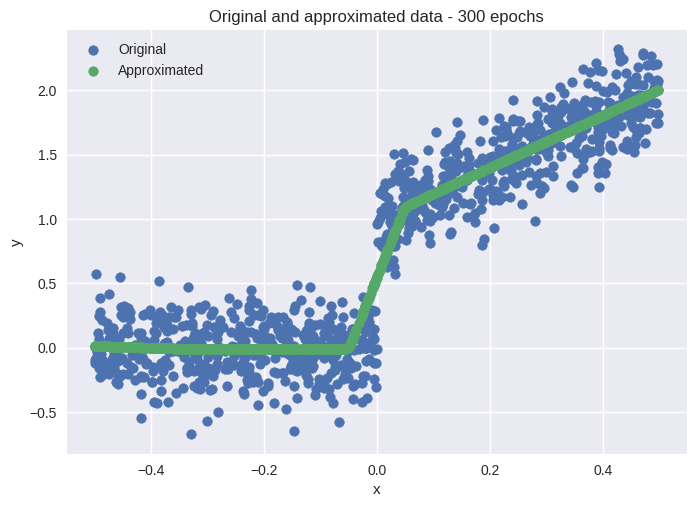

In [ ]:
preds=model.predict(Xdata)

plt.scatter(Xdata,Ydata);
plt.scatter(Xdata,preds);
plt.title('Original and approximated data - 300 epochs');
plt.xlabel('x');
plt.ylabel('y');
plt.legend(('Original','Approximated'));

Now initialize the model again and fit it, but train it for 1000 epochs.

In [ ]:
# Define the Fully-connected MLP
model = keras.Sequential([
    layers.Dense(5, activation="relu", input_shape=(1,), name="layer1"),
    layers.Dense(5, activation="relu", name="layer2"),
    layers.Dense(1, activation="linear", name="layer3"),
])

# Compile the model
model.compile(
    optimizer=keras.optimizers.SGD(learning_rate=0.01),
    loss='mse',
    metrics=['mse']
)

# Train the model
history_1000 = model.fit(Xdata, Ydata, epochs=1000)

Epoch 1/1000
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.9887 - mse: 0.9887
Epoch 2/1000
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.5028 - mse: 0.5028
Epoch 3/1000
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.4199 - mse: 0.4199
Epoch 4/1000
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.3572 - mse: 0.3572
Epoch 5/1000
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.3061 - mse: 0.3061
Epoch 6/1000
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.2501 - mse: 0.2501
Epoch 7/1000
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.1887 - mse: 0.1887
Epoch 8/1000
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.1569 - mse: 0.1569
Epoch 9/1000
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.1374 - mse: 0.1374
Epoch 10/1000
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.1047 - mse: 0.1047
Epoch 11/1000
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.1075 - mse: 0.1075
Epoch 12/1000
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0894 - mse: 0.0894
Epoch 13/1000
32/32 ━━━━━

Plot the original data and the predicted data. What are the differences observed with respect to the case before?

32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step


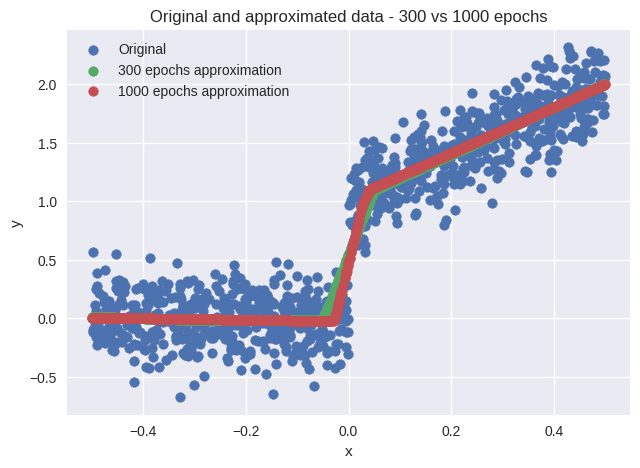

In [ ]:
preds_1000 = model.predict(Xdata)

plt.figure(figsize=(16, 5))
plt.subplot(1, 2, 1)
plt.scatter(Xdata,Ydata);
plt.scatter(Xdata,preds);
plt.scatter(Xdata,preds_1000);
plt.title('Original and approximated data - 300 vs 1000 epochs');
plt.xlabel('x');
plt.ylabel('y');
plt.legend(('Original','300 epochs approximation', '1000 epochs approximation'));

The approximation model that uses 1000 epochs gives us a profile more similar to the mathematical function that we wanted to implement, while the other approximation is less accurate in resembling the function we want.

What is the best loss achieved in this case?

In [ ]:
min_loss = np.min(history_1000.history['loss'])
min_loss_index = np.where(history_1000.history['loss'] == min_loss)

print('Minimum Loss on the Training Set: ', min_loss , ' obtained at epoch: ' , ''.join(map(str, min_loss_index[0]+1)) )#Index goes from 0 but epochs start at 1

Minimum Loss on the Training Set:  0.04531659558415413  obtained at epoch:  990


The minimum loss value with 1000 epochs is lower with respect to the model with 300 epochs: this is coherent with the previous comment, where the 1000-epochs model is better.

### **Exercise 3**: Classification

Generate synthetically two bivariate Gaussian vectors (see np.random.multivariate_normal), each one with 1000 samples:

*   Xdata0, with mean [-1,-1] and covariance [[4,0],[0,4]]
*   Xdata1, with mean [1,1] and covariance [[3,0],[0,3]]





In [3]:
# Bivariate Gaussian
mean0 = [-1, -1]
cov0 = [[4, 0], [0, 4]]

mean1 = [1, 1]
cov1 = [[3, 0], [0, 3]]

Xdata0 = np.random.multivariate_normal(mean0, cov0, 1000)
Xdata1 = np.random.multivariate_normal(mean1, cov1, 1000)

print(Xdata0.shape, Xdata1.shape)

(1000, 2) (1000, 2)


Expected output:
```
(1000, 2) (1000, 2)
```

From the above Gaussian vectors, stack them to generate a feature data matrix Xdatac with shape (2000,2) and the corresponding label vector Ydatac with zeros and ones of shape (2000,)

In [4]:
# Features
Xdatac = np.concatenate((Xdata0,Xdata1),axis=0)

# Labels
labels0 = np.zeros(Xdata0.shape[0])
labels1 = np.ones(Xdata1.shape[0])
labels_gt = np.concatenate((labels0,labels1),axis=0).T  # Ydatac

print(Xdatac.shape, labels_gt.shape)

(2000, 2) (2000,)


Expected output:
```
(2000, 2) (2000, 2)
```

Create a scatterplot of the two classes:

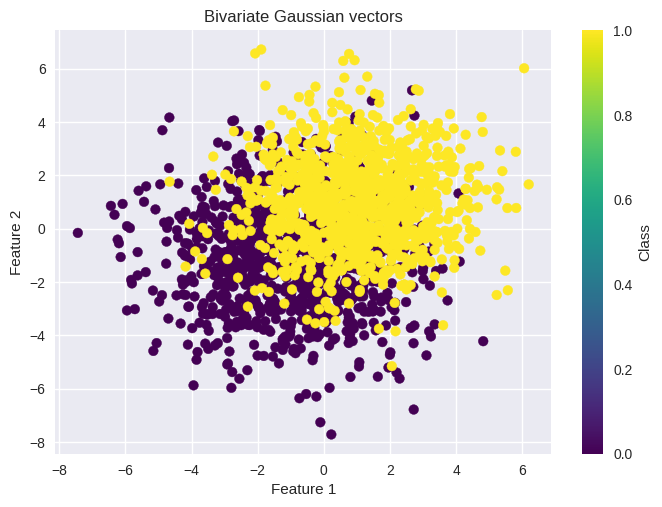

In [5]:
plt.scatter(Xdatac[:, 0], Xdatac[:, 1], c=labels_gt, cmap='viridis')
plt.title('Bivariate Gaussian vectors')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.colorbar(label='Class')     # only class 0 and class 1
plt.grid(True)
plt.show()

Divide the data Xdatac into a training partition and validation partition using "train_test_split" from sklearn. Use 30% of your data for validation.

In [6]:
from sklearn.model_selection import train_test_split

X_train, X_valid, y_train, y_valid = train_test_split(Xdatac, labels_gt, test_size=0.3)

Create a model identical to the one of Exercise 2 but use sigmoid activation in the output layer. You need also now to specify that the input has two values.

Train the model on the training partion. Select as loss function "binary_crossentropy" and monitor the training accuracy using metrics=["accuracy"]. Use also the validation partition to track the validation accuracy at each epoch.

In [9]:
# Define the Fully-connected MLP
model = keras.Sequential(
    [
        layers.Dense(5, activation="relu", input_shape=(2,), name="layer1"),
        layers.Dense(5, activation="relu", name="layer2"),
        layers.Dense(1, activation="sigmoid", name="layer3"),
    ]
)

# Compile the model
model.compile(
    optimizer=keras.optimizers.SGD(learning_rate=0.01),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# Train the model
history = model.fit(X_train, y_train, validation_data=(X_valid, y_valid), epochs=300)

Epoch 1/300
44/44 ━━━━━━━━━━━━━━━━━━━━ 3s 36ms/step - accuracy: 0.4037 - loss: 0.7294 - val_accuracy: 0.5933 - val_loss: 0.6570
Epoch 2/300
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.5817 - loss: 0.6505 - val_accuracy: 0.6450 - val_loss: 0.6146
Epoch 3/300
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.6184 - loss: 0.6276 - val_accuracy: 0.6883 - val_loss: 0.5877
Epoch 4/300
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7031 - loss: 0.5971 - val_accuracy: 0.7500 - val_loss: 0.5676
Epoch 5/300
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7479 - loss: 0.5778 - val_accuracy: 0.7550 - val_loss: 0.5526
Epoch 6/300
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7645 - loss: 0.5638 - val_accuracy: 0.7567 - val_loss: 0.5402
Epoch 7/300
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7572 - loss: 0.5542 - val_accuracy: 0.7583 - val_loss: 0.5302
Epoch 8/300
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7551 - loss: 0.5525 - val_accuracy: 0.7583 - 

Plot the training history showing the training accuracy and validation accuracy.

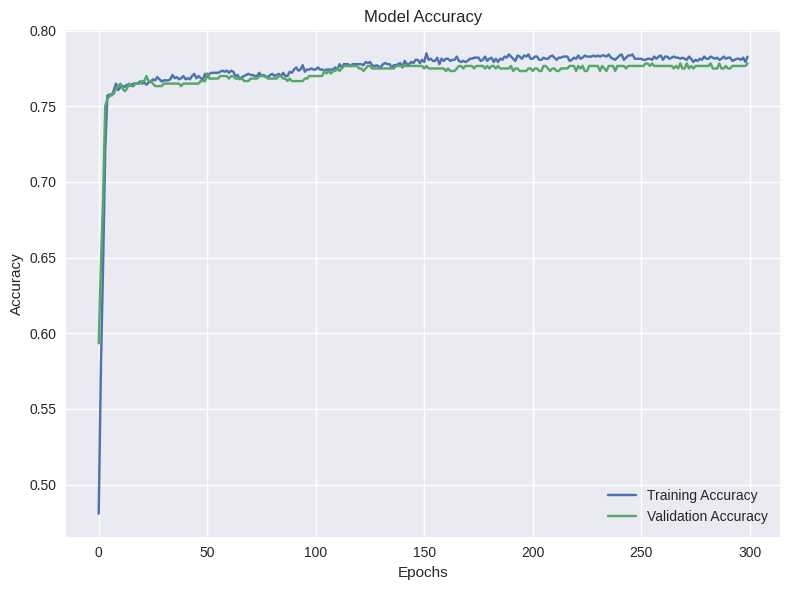

In [10]:
plt.figure(figsize=(8, 6))
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

plt.tight_layout()
plt.show()

Predict over the training data and create a scatter plot showing the predicted class for each data example.

44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step


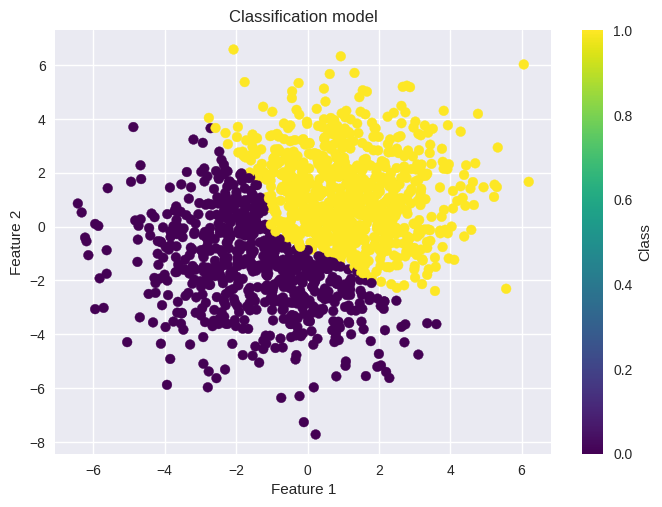

In [26]:
preds = model.predict(X_train)
preds_class = (preds > 0.5).astype(int)

plt.scatter(X_train[:, 0], X_train[:, 1], c=preds_class, cmap='viridis')
plt.title('Classification model')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.colorbar(label='Class')     # only class 0 and class 1

### **Exercise 4**: Data Preparation


Follow the same steps in Lab 2 to download the ESC-50 dataset.

In [28]:
!wget https://github.com/karolpiczak/ESC-50/archive/master.zip
!unzip master.zip

--2025-04-29 18:21:37--  https://github.com/karolpiczak/ESC-50/archive/master.zip
Resolving github.com (github.com)... 20.205.243.166
Connecting to github.com (github.com)|20.205.243.166|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://codeload.github.com/karolpiczak/ESC-50/zip/refs/heads/master [following]
--2025-04-29 18:21:38--  https://codeload.github.com/karolpiczak/ESC-50/zip/refs/heads/master
Resolving codeload.github.com (codeload.github.com)... 20.205.243.165
Connecting to codeload.github.com (codeload.github.com)|20.205.243.165|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: unspecified [application/zip]
Saving to: ‘master.zip’

master.zip              [         <=>        ] 615.78M  12.4MB/s    in 48s     

2025-04-29 18:22:26 (12.8 MB/s) - ‘master.zip’ saved [645695005]

Archive:  master.zip
33c8ce9eb2cf0b1c2f8bcf322eb349b6be34dbb6
   creating: ESC-50-master/
   creating: ESC-50-master/.circleci/
  inflating: E

Create a list of the files corresponding to the 10 first classes. Those files will form our dataset (400 signals).

In [29]:
fn_csv = 'ESC-50-master/meta/esc50.csv'
df = pd.read_csv(fn_csv)
df_10_classes = df[df['target'] < 10]   # take the first 10 classes

files = df_10_classes['filename'].tolist()
labels = np.array(df_10_classes['target'].tolist())

print(f'Lenghts: esc5_X: {len(files)}, esc5_y: {len(labels)}')

Lenghts: esc5_X: 400, esc5_y: 400


Expected output:

``` Lengths: esc5_X: 400, esc5_y: 400 ```

Convert the labels to class indexes (rank 1) - e.g. 0,1,2,....,9

In [ ]:
# already done in previous code

Create a list storing the signals from all the files:

In [30]:
path = 'ESC-50-master/audio/'
sr = librosa.get_samplerate(path + files[0])
signal = [librosa.load(path + file)[0] for file in files]

print(np.shape(signal))

(400, 110250)


For each signal in the list, compute the melspectrogram with librosa using default parameters:

In [31]:
mel_spegrams = [librosa.feature.melspectrogram(y=sig, sr=sr) for sig in signal]

Convert the list to a numpy array called Xdata. You should end up with an array of shape (400, 128, 216). What do these numbers mean?

In [32]:
Xdata = np.asarray(mel_spegrams)
Xdata.shape

(400, 128, 216)

Expected output:

```(400, 128, 216)```

400: Number of signals

128: Default number of frequency bins of mel-spectogram $n_\text{mels}$

216: Number of time frames from the mel-spectogram computation $n_\text{frames} = 1 + \lfloor \frac{110250}{512} \rfloor $

### **Exercise 5**: MLP Classification

Let's try now to classify the audio files by using the computed mel spectrogram data. First, flatten each spectrogram into a one-dimensional array, so that you end up with a new array Xdata_f of shape (400, 27648). You can do that by using the function reshape from numpy.

In [ ]:
Xdata_f = Xdata.reshape(Xdata.shape[0], -1)

print(Xdata_f.shape)

(400, 27648)


Expected output:
```
(400, 27648)
```

Let's first use the sklearn StandardScaler function to scale the data (save the output in Xdata_s)

In [ ]:
scaler = sklearn.preprocessing.StandardScaler()
Xdata_s = scaler.fit_transform(Xdata_f)

Create a test and validation split with 20% of the samples. Call the splits X_train, y_train, X_val, y_val.

In [ ]:
X_train, X_val, y_train, y_val = train_test_split(Xdata_s, labels, test_size=0.2)

Now, create a MLP-based network for classifying these audios. You can use the same layer structure as in the previous examples, but remember to adapt the output layer so that its size is equal to the number of classes and apply 'softmax' activation. You can also try to increase the number of neurons in the hidden layers.

Proposed architecture:

| Layer | Type  | Units | Activation | Output Shape           | Description                                  |
|-------|-------|-------|------------|-------------------------|----------------------------------------------|
| Input | Input | -     | -          | (None, shape_size)      | Input layer with `shape_size` features       |
| 1     | Dense | 16    | ReLU       | (None, 16)              | First hidden layer with 16 neurons           |
| 2     | Dense | 16    | ReLU       | (None, 16)              | Second hidden layer with 16 neurons          |
| 3     | Dense | 10    | Softmax    | (None, 10)              | Output layer for 10-class classification     |

In [ ]:
# Define the Fully-connected MLP
from keras.regularizers import l2, l1, l1_l2

model = keras.Sequential([
    layers.Dense(16, activation="relu", input_shape=(27648,), name="layer1"),
    # layers.Dense(16, activation="relu", input_shape=(27648,), name="layer1", kernel_regularizer=l2(0.001)),

    # layers.Dropout(0.15),

    layers.Dense(16, activation="relu", name="layer2",),
    # layers.Dense(16, activation="relu", name="layer2",kernel_regularizer=l2(0.001)),

    # layers.Dropout(0.10),

    layers.Dense(10, activation="softmax", name="layer3"),
])

/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Fit the model using "sparse_categorical_crossentropy" as loss function. Probably your first attempts will overfit.

Try different strategies to prevent overfitting:

*   Dropout
*   Regularization
*   Reduce number of neurons/layers

What is the best accuracy you could get with a fully-based MLP network?

*The answer is presented in the observation at the end of the exercise*


In [ ]:
# Compile the model
model.compile(
    optimizer=keras.optimizers.SGD(learning_rate=0.01),     # adam alternative
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Train the model
history = model.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=300)

# Print the best accuracy
max_acc = np.max(history.history['accuracy'])
max_acc_index = np.where(history.history['accuracy'] == max_acc)

print('Maximum Accuracy on the Training Set: ', max_acc , ' obtained at epoch: ' , ''.join(map(str, max_acc_index[0]+1)) ) #Index goes from 0 but epochs start at 1

Epoch 1/300
10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 92ms/step - accuracy: 0.1239 - loss: 2.4608 - val_accuracy: 0.1500 - val_loss: 2.4197
Epoch 2/300
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.3300 - loss: 1.7850 - val_accuracy: 0.2250 - val_loss: 2.2811
Epoch 3/300
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.4288 - loss: 1.5661 - val_accuracy: 0.2500 - val_loss: 2.1813
Epoch 4/300
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.5784 - loss: 1.3359 - val_accuracy: 0.2750 - val_loss: 2.1396
Epoch 5/300
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.6342 - loss: 1.1744 - val_accuracy: 0.3250 - val_loss: 2.0808
Epoch 6/300
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.6920 - loss: 1.0222 - val_accuracy: 0.3125 - val_loss: 2.0496
Epoch 7/300
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.7475 - loss: 0.9873 - val_accuracy: 0.3125 - val_loss: 2.0336
Epoch 8/300
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.7194 - loss: 0.9058 - val_accuracy: 0.2875 -

Which is the minimum loss achieved by the model? At which epoch achieved that loss value?

In [ ]:
min_loss = np.min(history.history['loss'])
min_loss_index = np.where(history.history['loss'] == min_loss)

print('Minimum Loss on the Training Set: ', min_loss , ' obtained at epoch: ' , ''.join(map(str, min_loss_index[0]+1)) ) #Index goes from 0 but epochs start at 1

Minimum Loss on the Training Set:  0.05828087404370308  obtained at epoch:  290


Plot the training history of the network, showing the evolution of the training/validation loss.

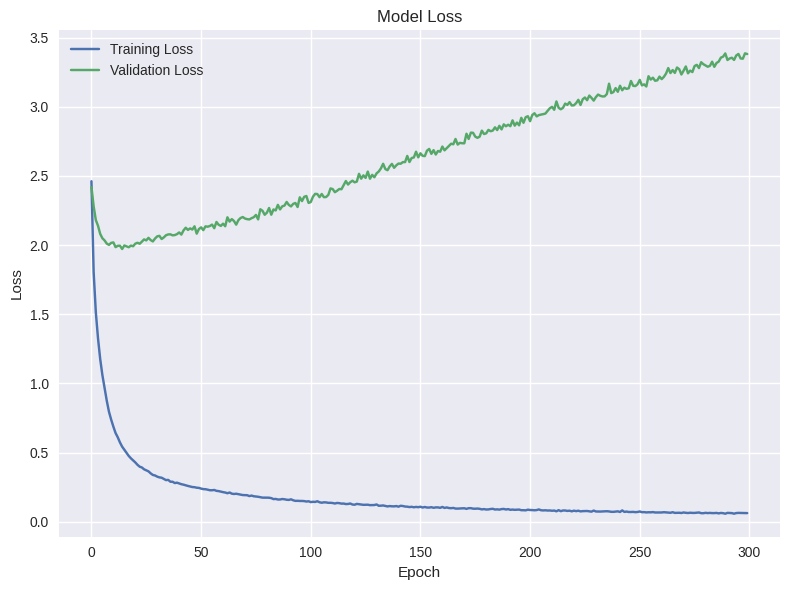

In [ ]:
plt.figure(figsize=(8, 6))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.tight_layout()
plt.show()

### Observations

At first, we try the default model: we observe strong overfitting, given a 95% training accuracy and 40% validation accuracy.

To improve this, let's first try reducing the model size, so to reduce the complexity and make the classification more general.
We try with 5 neurons per each hidden layer: we don't get better results, with 90% and 30% respectively (for training and validation accuracies).
Using 10 neurons is not that better: we obtain 95% and 35% accuracies.

Let's introduce the *dropout* parameter: we try to avoid any overfitting by temporarily disable some of the model neurons during the training, forcing it to find a more robust distributed configuration.
We try dropout of 20% (with 16 neurons per layer): we obtain 90% and 40% accuracies.
With respect to the default model, we get a bit less training accuracy: it is harder to train the model, but the model results more robust - only good changes remain.
The problem of using the dropout is visible when we try 40% of dropout: the results are 70% and 30%.
High dropout rates reduce the effective model capacity during training, requiring more epochs for the model to convergence towards the optimal case.

Let's introduce the *regularization* parameter: we impose certain constraints upon the distribution of the model's weights - for example, we avoid having weights much greater than others.
Applying the different regularizations upon the original model (with 16 neurons per layer, without dropout) is not that helpful to overcome the overfitting.

So, we try mixing different parameters to obtain better accuracy values: in general, it is better to use regularization, and the dropout should be lower than 20% in order to keep a high accuracy.


As a last resort, we try changing the optimizer into *adam*: the training accuracy gets higher, but not the validation accuracy, so the overfitting problem stays unsolved.


<span style="color: red;">I am missing some figures at least with the best performing approach to see if the model is converging or not. Have you tried combining approaches (e.g. dropout+L2)?</span>

### **Exercise 6**: CNN

Create training and validation partitions from Xdata. Remember that Xdata stores has size (400, 128, 216), storing 400 Mel spectrograms of sie (128,216). Name the partitions X_train, X_test, y_train and y_test.

In [34]:
X_train, X_test, y_train, y_test = train_test_split(Xdata,labels, test_size=0.2)

print(X_train.shape, y_train.shape, X_test.shape, y_test.shape)

(320, 128, 216) (320,) (80, 128, 216) (80,)


Scale each spectrogram by substracting its mean and dividing by its standard deviation.

In [35]:
scaler = sklearn.preprocessing.StandardScaler()
X_train_s = [StandardScaler().fit_transform(data) for data in X_train]
X_test_s = [StandardScaler().fit_transform(data) for data in X_test]

X_train_s = np.asarray(X_train_s)
X_test_s = np.asarray(X_test_s)

Create a convolutional neural network model. Remember to adapt the input shape of the first layer to the new input.

You can start with a model like the next one. Remember to include regularization strategies like dropout layers.

| Layer | Type        | Filters/Units | Kernel/Pool Size | Activation | Output Shape        | Description                                  |
|-------|-------------|----------------|------------------|------------|---------------------|----------------------------------------------|
| Input | Input        | -              | -                | -          | (None, H, W, C)      | Input shape from `X_train_sx.shape[1:]`      |
| 1     | Conv2D       | 16             | (3, 3)           | ReLU       | (None, H-2, W-2, 16) | First convolutional layer                    |
| 2     | MaxPooling2D | -              | (3, 3), stride 3 | -          | (None, H//3, W//3, 16) | Downsamples feature maps                     |
| 3     | Conv2D       | 16             | (3, 3)           | ReLU       | (None, ..., ..., 16) | Second convolutional layer                   |
| 4     | MaxPooling2D | -              | (2, 2), stride 2 | -          | (None, ..., ..., 16) | Second pooling layer                         |
| 5     | Conv2D       | 32             | (2, 2)           | ReLU       | (None, ..., ..., 32) | Third convolutional layer                    |
| 6     | Flatten      | -              | -                | -          | (None, N)            | Flattens 2D features to 1D vector            |
| 7     | Dense        | 32             | -                | ReLU       | (None, 32)           | Fully connected hidden layer                 |
| 8     | Dropout      | -              | -                | -          | (None, 32)           | Dropout for regularization (rate=0.1)        |
| 9     | Dense        | 10             | -                | Softmax    | (None, 10)           | Output layer for 10-class classification     |

In [36]:
# expanding X_train_s and X_test_s to fit conv2d
X_train_sx = np.expand_dims(X_train_s, axis=-1)
X_test_sx = np.expand_dims(X_test_s, axis=-1)

In [37]:
model = keras.Sequential([
    layers.Input(shape=(128, 216, 1)),

    layers.Conv2D(16, (3, 3), activation='relu'),

    layers.MaxPooling2D((3, 3), strides=3),

    layers.Conv2D(16, (3, 3), activation='relu'),

    layers.MaxPooling2D((2, 2), strides=2),

    layers.Conv2D(32, (2, 2), activation='relu'),

    layers.Flatten(),

    layers.Dense(32, activation='relu'),
    layers.Dropout(0.4),

    layers.Dense(10, activation='softmax')
])

model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 214, 16)   │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 42, 71, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 40, 69, 16)     │         2,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 20, 34, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 19, 33, 32)     │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 20064)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │       642,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 646,970 (2.47 MB)

 Trainable params: 646,970 (2.47 MB)

 Non-trainable params: 0 (0.00 B)

Fit the model and try to improve the results obtained with the MLP model.

In [38]:
#compile the model
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.00005),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

#fit the model
history = model.fit(X_train_sx, y_train, validation_data=(X_test_sx, y_test), batch_size=32, epochs=100)

Epoch 1/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 7s 175ms/step - accuracy: 0.1544 - loss: 2.3094 - val_accuracy: 0.3750 - val_loss: 2.1446
Epoch 2/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 5s 18ms/step - accuracy: 0.2801 - loss: 2.1015 - val_accuracy: 0.4250 - val_loss: 2.0361
Epoch 3/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.3633 - loss: 1.9981 - val_accuracy: 0.4125 - val_loss: 1.9290
Epoch 4/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.3871 - loss: 1.8656 - val_accuracy: 0.4875 - val_loss: 1.8343
Epoch 5/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.4514 - loss: 1.7914 - val_accuracy: 0.5000 - val_loss: 1.7503
Epoch 6/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.4974 - loss: 1.6248 - val_accuracy: 0.4500 - val_loss: 1.6803
Epoch 7/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.5194 - loss: 1.6143 - val_accuracy: 0.4500 - val_loss: 1.6212
Epoch 8/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.4642 - loss: 1.5330 - val_accuracy: 0

Plot the training history (train/val loss/accuracy)

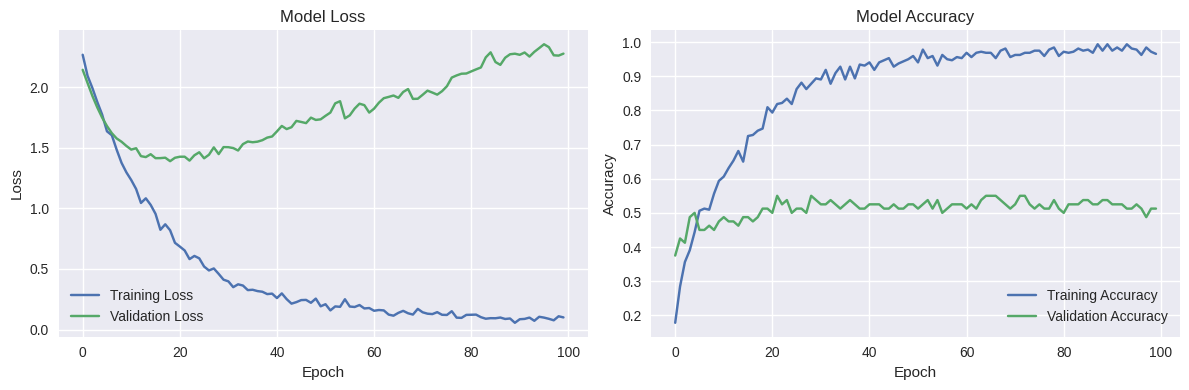

In [39]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.tight_layout()
plt.show()

Which is the minimum loss achieved by the model? At which epoch achieved that loss value?

In [40]:
min_val_loss = np.min(history.history['val_loss'])
min_val_loss_index = np.where(history.history['val_loss'] == min_val_loss)
val_accuracy_history = history.history['val_accuracy']


print('Minimum Loss on the Validation Set: ', min_val_loss ,' obtained at epoch: ' , ''.join(map(str, min_val_loss_index[0]+1)), '  with an Accuracy of: ', val_accuracy_history[int(min_val_loss_index[0].item())] )#Index goes from 0 but epochs start at 1

Minimum Loss on the Validation Set:  1.3902699947357178  obtained at epoch:  19   with an Accuracy of:  0.512499988079071


Tune your model and try to achieve an accuracy above 60%.

Model: "sequential_46"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_132 (Conv2D)             │ (None, 126, 214, 16)   │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_208 (Dropout)           │ (None, 126, 214, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_88 (MaxPooling2D) │ (None, 42, 71, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_133 (Conv2D)             │ (None, 40, 69, 16)     │         2,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_54          │ (None, 40, 69, 16)     │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_209 (Dropout)           │ (None, 40, 69, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_89 (MaxPooling2D) │ (None, 20, 34, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_134 (Conv2D)             │ (None, 19, 33, 32)     │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_210 (Dropout)           │ (None, 19, 33, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_44 (Flatten)            │ (None, 20064)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_121 (Dense)               │ (None, 16)             │       321,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_211 (Dropout)           │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_122 (Dense)               │ (None, 32)             │           544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_212 (Dropout)           │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_123 (Dense)               │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 326,538 (1.25 MB)

 Trainable params: 326,506 (1.25 MB)

 Non-trainable params: 32 (128.00 B)

Epoch 1/150
10/10 ━━━━━━━━━━━━━━━━━━━━ 16s 119ms/step - accuracy: 0.1122 - loss: 25.9175 - val_accuracy: 0.3000 - val_loss: 14.0757
Epoch 2/150
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - accuracy: 0.2123 - loss: 11.8775 - val_accuracy: 0.2750 - val_loss: 8.2378
Epoch 3/150
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.2555 - loss: 7.3196 - val_accuracy: 0.2375 - val_loss: 5.6078
Epoch 4/150
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.3012 - loss: 5.0227 - val_accuracy: 0.2750 - val_loss: 4.4307
Epoch 5/150
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.2838 - loss: 4.0246 - val_accuracy: 0.2375 - val_loss: 3.9757
Epoch 6/150
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.3323 - loss: 3.5177 - val_accuracy: 0.2500 - val_loss: 3.8232
Epoch 7/150
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.2956 - loss: 3.4883 - val_accuracy: 0.2750 - val_loss: 3.7570
Epoch 8/150
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.3668 - loss: 3.2840 - val_accurac

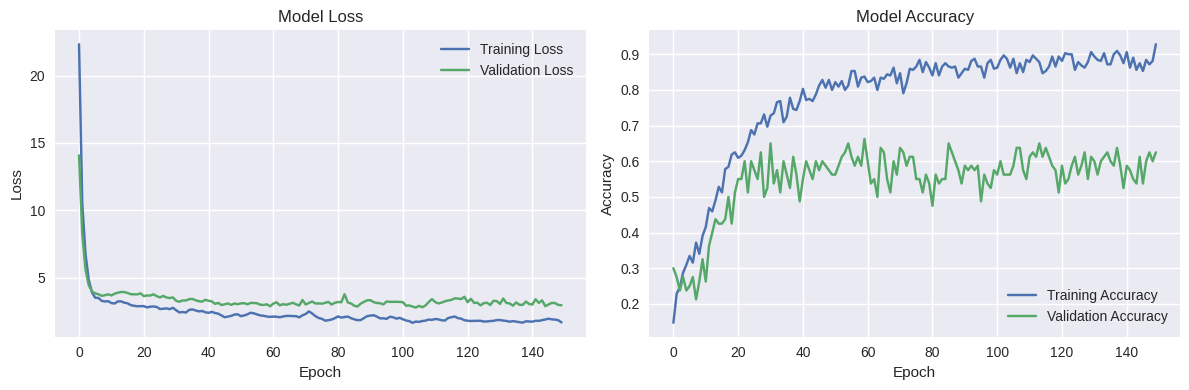

In [ ]:
model = keras.Sequential([
    layers.Input(shape=(128, 216, 1)),

    layers.Conv2D(16, (3, 3), activation='relu'),
    #layers.BatchNormalization(),
    layers.Dropout(0.1),

    layers.MaxPooling2D((3, 3), strides=3),

    layers.Conv2D(16, (3, 3), activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.2),

    layers.MaxPooling2D((2, 2), strides=2),

    layers.Conv2D(32, (2, 2), activation='relu'),
    #layers.BatchNormalization(),
    layers.Dropout(0.1),

    layers.Flatten(),

    #We add an extra layer in between to reduce the number of parameters (aproximately by half) and make the model faster
    #It also helps to reduce the overfitting, despite now the training accuracy it's a little bit lower
    layers.Dense(16, activation='relu', kernel_regularizer=l1_l2(0.01)),
    layers.Dropout(0.3),

    layers.Dense(32, activation='relu', kernel_regularizer=l1(0.001)),
    layers.Dropout(0.1),

    layers.Dense(10, activation='softmax')
])

model.summary()

#compile the model
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

#fit the model
history = model.fit(X_train_sx, y_train, validation_data=(X_test_sx, y_test), batch_size=32, epochs=150) #Increase the epochs, model seems to still learn in the last epochs

# Plot loss and accuracy
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.tight_layout()
plt.show()